In [2]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.stats import binom
from mp1lib import packet_errors 

Bernouli trials and the binomial
Sample mean:      5.003350
Theoretical mean: 5.000000
Mean Difference:  0.003350

Sample Variance: 4.965208
Theoretical Variance: 4.975000
Variance: -0.009792


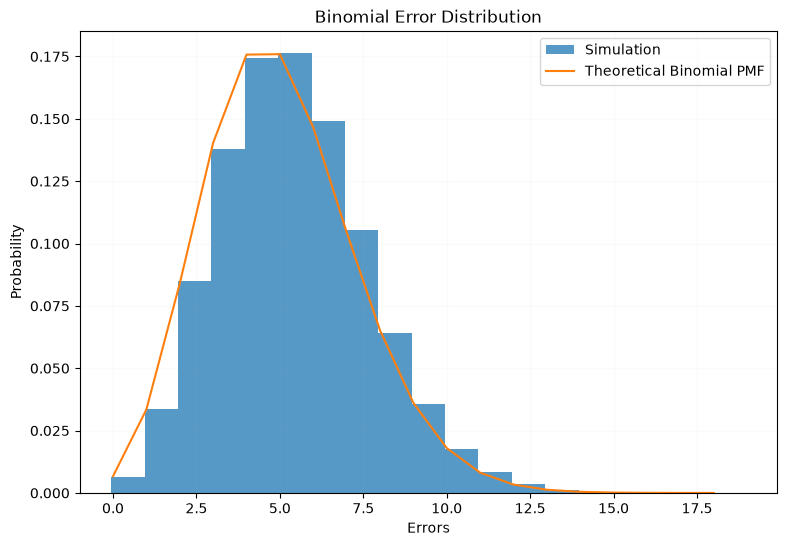


Clean Packet Probabilities
p = 0.005
Theoretical Probability: 0.006654
Emperical Probability:   0.006730
Difference:              0.000076
Error:                   0.000257

p = 0.001
Theoretical Probability: 0.367695
Emperical Probability:   0.369530
Difference:              0.001835
Error:                   0.001525

p = 0.0001
Theoretical Probability: 0.904833
Emperical Probability:   0.903790
Difference:              -0.001043
Error:                   0.000928



In [9]:
# unique group seed 
SEED = 5 
rng = np.random.default_rng(SEED)
rng4 = rng.spawn(1)[0]

#pararmeters
N_pkt = 100000
N_bits = 1000
P_error = .005

errors = packet_errors( 
    n_pkt = N_pkt,
    n_bits = N_bits,
    p = P_error,
    rng  = rng4
)

#calculations 
sample_mean = np.mean(errors)
sample_var = np.var(errors, ddof =1)
theoretical_mean = N_bits * P_error
theoretical_var = N_bits * P_error * (1 - P_error) 
mean_diff = sample_mean - theoretical_mean
var_diff = sample_var - theoretical_var
mean_error = np.sqrt(theoretical_var / N_pkt)

print("Bernouli trials and the binomial") 
print(f"Sample mean:      {sample_mean:.6f}")
print(f"Theoretical mean: {theoretical_mean:.6f}")
print(f"Mean Difference:  {mean_diff:.6f}")
print()
print(f"Sample Variance: {sample_var:.6f}")
print(f"Theoretical Variance: {theoretical_var:.6f}")
print(f"Variance: {var_diff:.6f}")

#plot
plt.figure(figsize = (9,6)) 
plt.hist(
    errors,
    bins = np.arange(errors.max() +2) -.05,
    density = True,
    alpha = .75,
    label = "Simulation"
)

k_values = np.arange(0,errors.max()+1) 

binomial_pmf = binom.pmf(
    k_values,
    n = N_bits,
    p = P_error
)

plt.plot(
    k_values,
    binomial_pmf,
    markersize = 5,
    label = "Theoretical Binomial PMF"
)

plt.xlabel("Errors")
plt.ylabel("Probability")
plt.title("Binomial Error Distribution")
plt.legend()
plt.grid(alpha = .05)
plt.show()

print()
print("Clean Packet Probabilities")

p_val = [.005, .001, .0001]
for p in p_val: 
    packet_error_clean = packet_errors(
    n_pkt = N_pkt,
    n_bits = N_bits,
    p = p,
    rng = rng4
    )
    theoretical_clean = (1 - p) ** N_bits
    emperical_clean = np.mean(packet_error_clean == 0)
    difference = emperical_clean - theoretical_clean
    Error = np.sqrt( theoretical_clean * (1 -theoretical_clean) / N_pkt)
    
    print(f"p = {p}")
    print(f"Theoretical Probability: {theoretical_clean:.6f}")
    print(f"Emperical Probability:   {emperical_clean:.6f}")
    print(f"Difference:              {difference:.6f}")
    print(f"Error:                   {Error:.6f}")
    print()